<a href="https://colab.research.google.com/github/darialgt/MN/blob/main/%D0%9B%D0%A05_%D0%9C%D0%B0%D1%82%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки
!pip -q install kagglehub prophet

import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from prophet import Prophet
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense


In [2]:
# Завантажте датасет з Kaggle
data_dir = Path(kagglehub.dataset_download(
    'yug201/daily-climate-time-series-data-delhi-india'
))
csv_path = next(data_dir.rglob('kaggel_weather_2013_to_2024.csv'))
csv_path


Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.


PosixPath('/kaggle/input/daily-climate-time-series-data-delhi-india/kaggel_weather_2013_to_2024.csv')

In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані
df = pd.read_csv(csv_path)
display(df.head())
display(df.describe(include='all'))


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
unique,NaN,3556,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,5/1/2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,1778.000000,NaN,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,NaN,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,NaN,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,NaN,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,NaN,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,NaN,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622


Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу

df.columns = df.columns.str.strip()
df['DATE'] = pd.to_datetime(df['DATE'])
df = (df.sort_values('DATE')
        .drop(columns=['Unnamed: 0'], errors='ignore')
        .set_index('DATE'))
temp_col = 'temp'


In [5]:
# Перегляньте інформацію про структуру датасету

df.info()


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  month                  3557 non-null  

In [6]:
# Перевірте наявність пропущених значень

display(df.isna().sum())
numeric_cols = df.select_dtypes(include='number').columns
df[numeric_cols] = df[numeric_cols].interpolate().bfill().ffill()
df = df.bfill().ffill()


,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0
precipcover,0


Графік температури

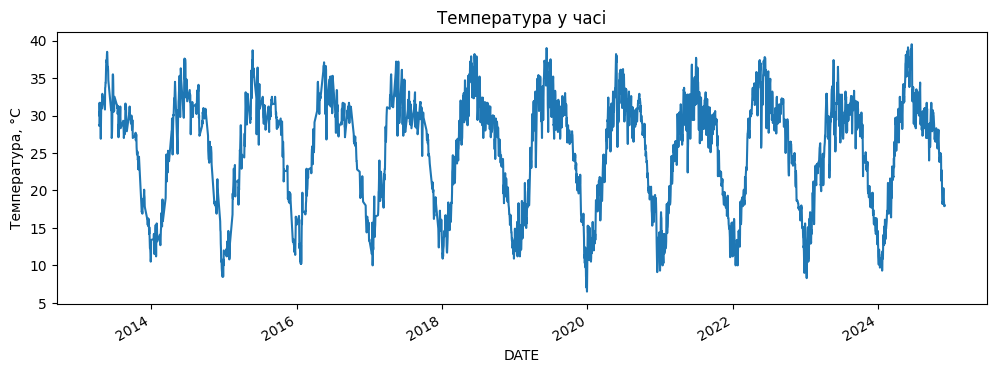

In [7]:
# Побудуйте графік зміни температури у часі

df[temp_col].plot(figsize=(12, 4), title='Температура у часі')
plt.ylabel('Температура, °C')
plt.show()


Ковзне середнє

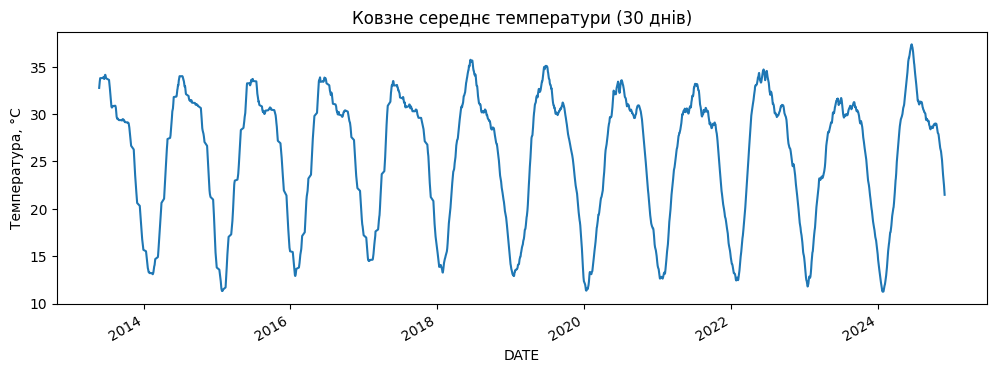

In [8]:
# Обчисліть та візуалізуйте ковзне середнє температури

df[temp_col].rolling(30).mean().plot(figsize=(12, 4), title='Ковзне середнє температури (30 днів)')
plt.ylabel('Температура, °C')
plt.show()


Розподіл температури

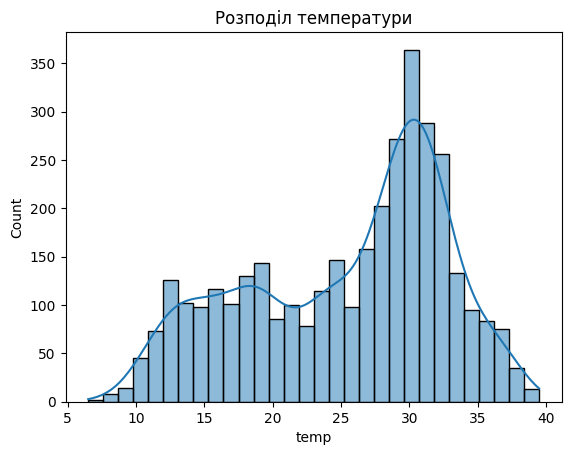

In [9]:
# Побудуйте гістограму розподілу температури

sns.histplot(df[temp_col], bins=30, kde=True)
plt.title('Розподіл температури')
plt.show()


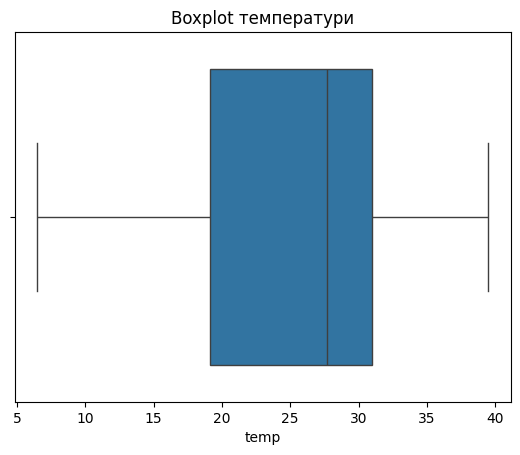

In [10]:
# Побудуйте boxplot температури для аналізу викидів

sns.boxplot(x=df[temp_col])
plt.title('Boxplot температури')
plt.show()


Аналіз автокореляції
ACF

PACF

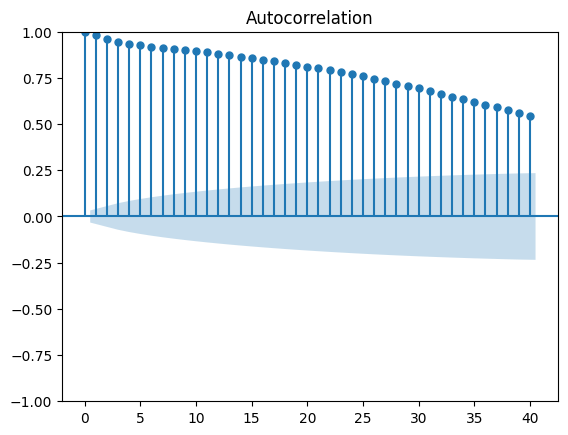

In [11]:
# Побудуйте графік автокореляційної функції (ACF)

plot_acf(df[temp_col], lags=40)
plt.show()


Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

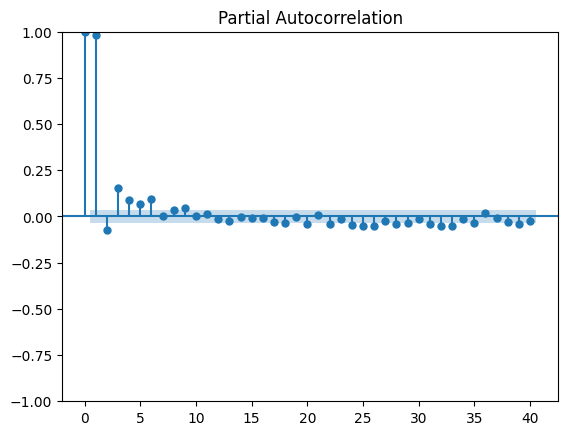

In [12]:
# Побудуйте графік часткової автокореляційної функції (PACF)

plot_pacf(df[temp_col], lags=40, method='ywm')
plt.show()


Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [13]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку

series = df[temp_col].astype(float)
split = int(len(series) * 0.8)
train, test = series.iloc[:split], series.iloc[split:]
print(len(train), len(test))


2845 712


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [16]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки

arima_fit = ARIMA(train, order=(2, 1, 2)).fit()
arima_pred = pd.Series(arima_fit.forecast(len(test)).to_numpy(), index=test.index)


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


ValueError: No supported index is available.

In [15]:
# Виведіть статистичний звіт навченої ARIMA-моделі

print(arima_fit.summary())


                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 2845
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -4973.500
Date:                Fri, 23 Oct 2026   AIC                           9956.999
Time:                        12:44:37   BIC                           9986.764
Sample:                             0   HQIC                          9967.735
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7179      0.082      8.716      0.000       0.556       0.879
ar.L2         -0.1784      0.075     -2.378      0.017      -0.325      -0.031
ma.L1         -0.6778      0.083     -8.122      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

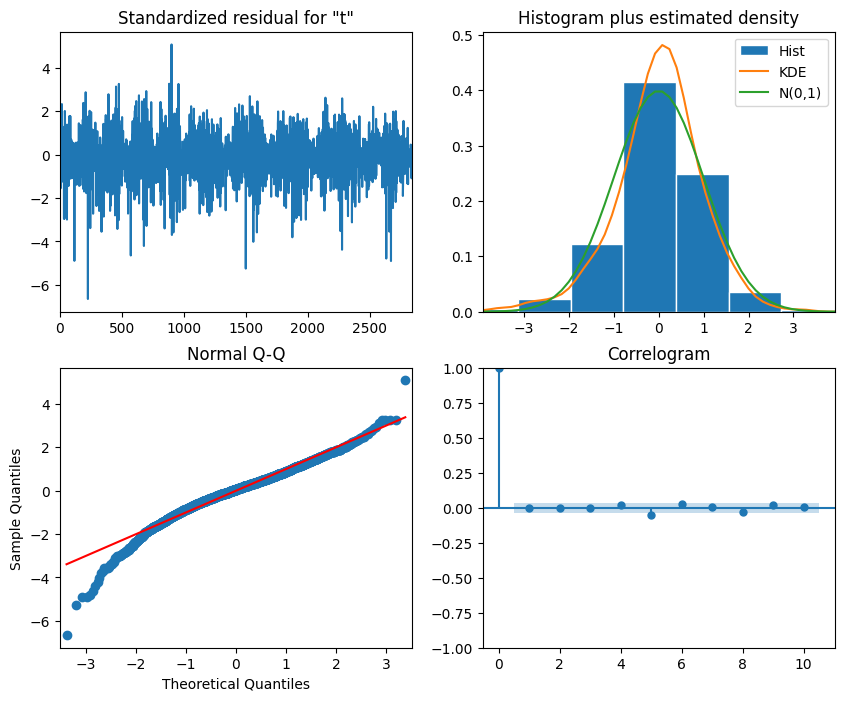

In [17]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки

arima_fit.plot_diagnostics(figsize=(10, 8))
plt.show()


In [18]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA

def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

metrics = {}
metrics['ARIMA'] = {
    'MAE': mean_absolute_error(test, arima_pred),
    'RMSE': np.sqrt(mean_squared_error(test, arima_pred)),
    'MAPE': mape(test, arima_pred)
}
metrics['ARIMA']


NameError: name 'arima_pred' is not defined

NameError: name 'arima_pred' is not defined

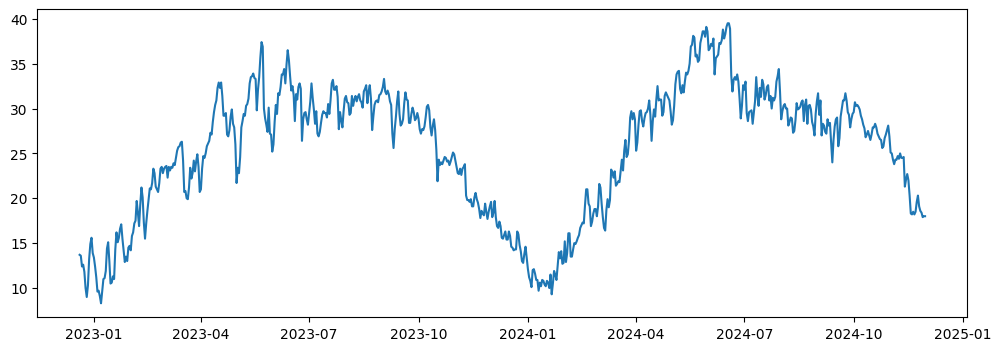

In [19]:
# Візуалізуйте фактичні значення та прогноз ARIMA

plt.figure(figsize=(12, 4))
plt.plot(test, label='Фактичні')
plt.plot(arima_pred, label='ARIMA')
plt.legend()
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [20]:
# Підготуйте дані у форматі, необхідному для Prophet

prophet_train = train.rename_axis('ds').reset_index(name='y')


In [21]:
# Створіть та навчіть модель Prophet

prophet_model = Prophet(daily_seasonality=False, weekly_seasonality=True, yearly_seasonality=True)
prophet_model.fit(prophet_train)


Прогноз

In [22]:
# Побудуйте прогноз Prophet для тестового періоду

prophet_forecast = prophet_model.predict(pd.DataFrame({'ds': test.index}))
prophet_pred = pd.Series(prophet_forecast['yhat'].to_numpy(), index=test.index)


In [23]:
# Обчисліть MAE, RMSE, MAPE для Prophet

metrics['Prophet'] = {
    'MAE': mean_absolute_error(test, prophet_pred),
    'RMSE': np.sqrt(mean_squared_error(test, prophet_pred)),
    'MAPE': mape(test, prophet_pred)
}
metrics['Prophet']


{'MAE': 2.004679994301011,
 'RMSE': np.float64(2.5901965298397274),
 'MAPE': np.float64(9.027934868552647)}

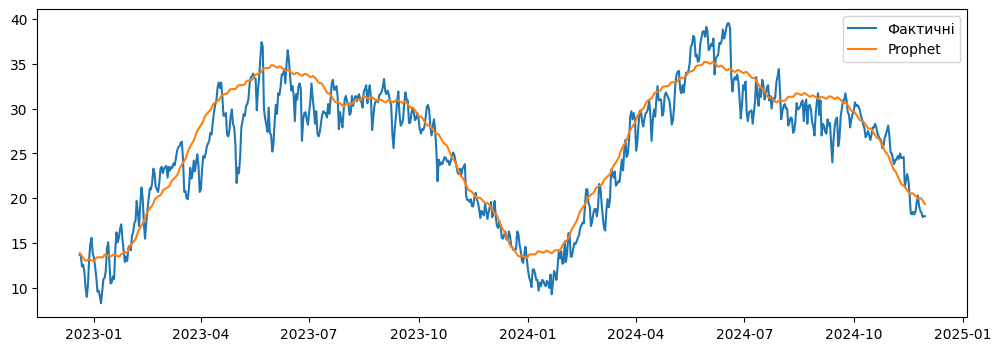

In [24]:
# Візуалізуйте фактичні значення та прогноз Prophet

plt.figure(figsize=(12, 4))
plt.plot(test, label='Фактичні')
plt.plot(prophet_pred, label='Prophet')
plt.legend()
plt.show()


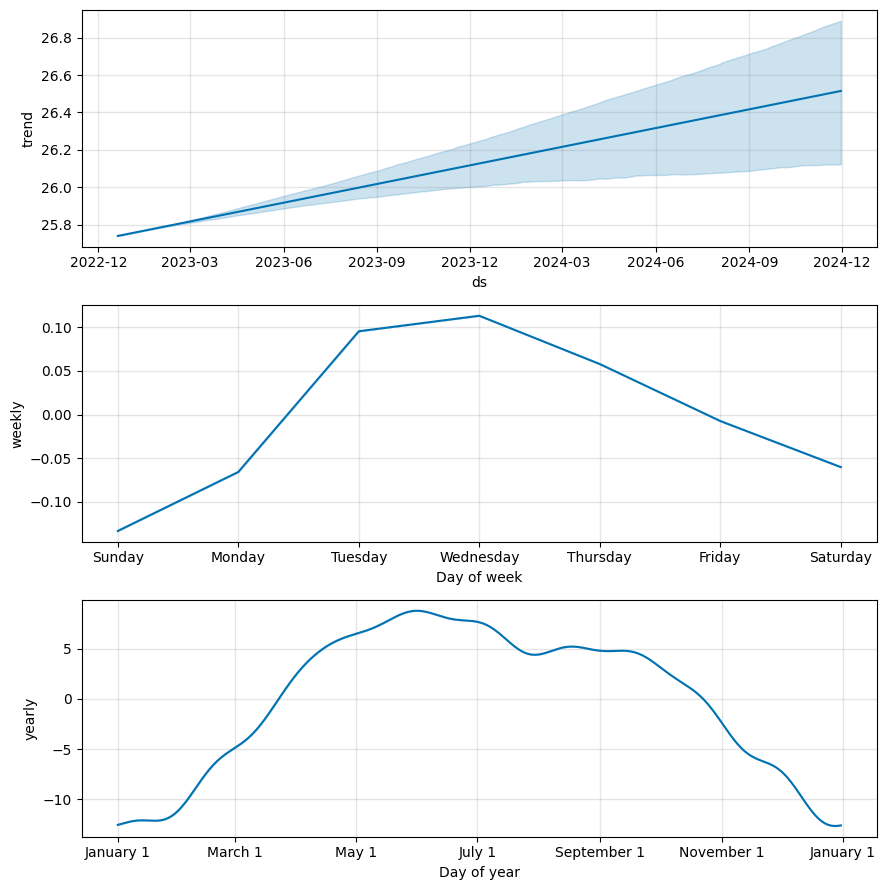

In [25]:
# Побудуйте компоненти моделі Prophet

prophet_model.plot_components(prophet_forecast)
plt.show()


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [26]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM

window = 30
scaler = MinMaxScaler().fit(train.to_numpy().reshape(-1, 1))
scaled = scaler.transform(series.to_numpy().reshape(-1, 1))

def make_sequences(data, size):
    X, y = [], []
    for i in range(size, len(data)):
        X.append(data[i-size:i])
        y.append(data[i])
    return np.array(X), np.array(y)

X_all, y_all = make_sequences(scaled, window)
sequence_dates = series.index[window:]


In [27]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування

split_seq = split - window
X_train, X_test = X_all[:split_seq], X_all[split_seq:]
y_train, y_test = y_all[:split_seq], y_all[split_seq:]


In [28]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її

lstm_model = Sequential([
    LSTM(32, input_shape=(window, 1)),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')


In [29]:
# Навчіть LSTM-модель

history = lstm_model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=0
)


In [30]:
# Виведіть структуру LSTM-моделі

lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,157 (51.40 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,772 (34.27 KB)

In [31]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування

lstm_pred = scaler.inverse_transform(lstm_model.predict(X_test, verbose=0)).ravel()


In [32]:
# Сформуйте часові мітки для тестового прогнозу LSTM

lstm_dates = sequence_dates[split_seq:]
lstm_actual = series.loc[lstm_dates]
lstm_pred = pd.Series(lstm_pred, index=lstm_dates)


In [33]:
# Обчисліть MAE, RMSE, MAPE для LSTM

metrics['LSTM'] = {
    'MAE': mean_absolute_error(lstm_actual, lstm_pred),
    'RMSE': np.sqrt(mean_squared_error(lstm_actual, lstm_pred)),
    'MAPE': mape(lstm_actual, lstm_pred)
}
metrics['LSTM']


{'MAE': 1.459770674384042,
 'RMSE': np.float64(1.8722178722440144),
 'MAPE': np.float64(6.360277205122541)}

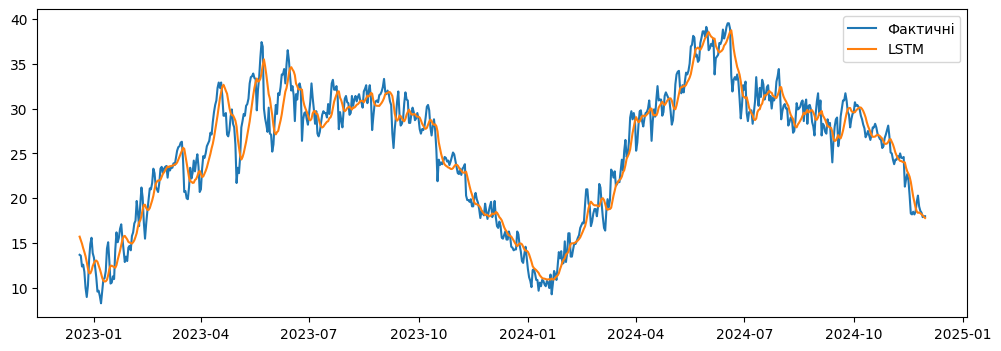

In [34]:
# Візуалізуйте фактичні значення та прогноз LSTM

plt.figure(figsize=(12, 4))
plt.plot(lstm_actual, label='Фактичні')
plt.plot(lstm_pred, label='LSTM')
plt.legend()
plt.show()


Порівняння моделей

,MAE,RMSE,MAPE
Prophet,2.005,2.590,9.028
LSTM,1.460,1.872,6.360


Найкраща модель за RMSE: LSTM


NameError: name 'arima_pred' is not defined

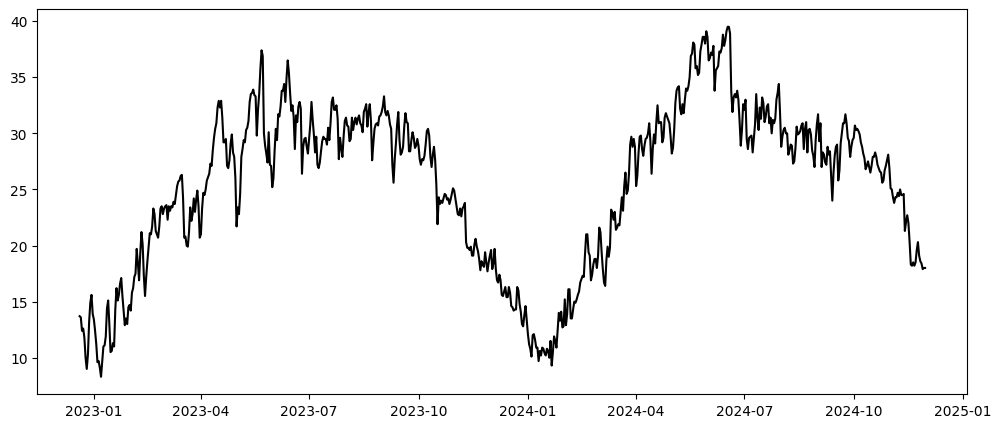

In [35]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами

results = pd.DataFrame(metrics).T.round(3)
display(results)
best_model = results['RMSE'].idxmin()
print(f'Найкраща модель за RMSE: {best_model}')

plt.figure(figsize=(12, 5))
plt.plot(test, label='Фактичні', color='black')
plt.plot(arima_pred, label='ARIMA')
plt.plot(prophet_pred, label='Prophet')
plt.plot(lstm_pred, label='LSTM')
plt.legend()
plt.show()


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.

Дані підготовлено та проаналізовано за допомогою графіків, ACF і PACF. Побудовано моделі ARIMA, Prophet та LSTM. Їх якість порівняно за MAE, RMSE і MAPE; найкращу модель визначено в таблиці за найменшим RMSE.